# Limits of K-means clustering

In [1]:
import numpy as np
from skimage import img_as_ubyte
# import matplotlib.pyplot as plt


import skimage.io as io
# from skimage import img_as_ubyte
# from skimage.color import rgb2gray
import matplotlib.pyplot as plt
# import numpy as np
# from skimage.filters import threshold_otsu
# from skimage.transform import resize

# import matplotlib as mpl
plt.style.use('../../src/bip.mplstyle')
# mpl.rcParams['xtick.bottom'] = False
# mpl.rcParams['ytick.left'] = False
# plt.rcParams['image.cmap'] = 'gray'

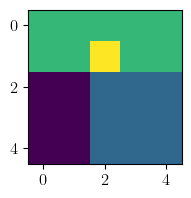

In [5]:
# Image cadre (couleurs à affecter)
c = np.array([
    [2, 2, 2, 2, 2],
    [2, 2, 3, 2, 2],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 1],
])
plt.figure(figsize=(2,2))
plt.imshow(c)
plt.show()

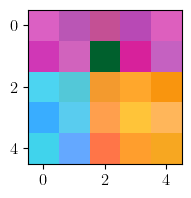

In [6]:
# Image observée

# Couleurs types
colors = np.array([
    [76, 198, 244],
    [255, 153, 51],
    [210, 76, 180],
    [0, 128, 50],
])/255

# Image non bruitée
M, N = c.shape
img = np.zeros((M,N,3))
for m in range(M):
    for n in range(N):
        img[m,n,:] = colors[c[m,n]]        
        
# Image bruitée
img += np.random.normal(0,.07,img.shape)
img = np.clip(img, 0, 1)
img = img_as_ubyte(img)

# Affichage
plt.figure(figsize=(2,2))
plt.imshow(img)
plt.show()

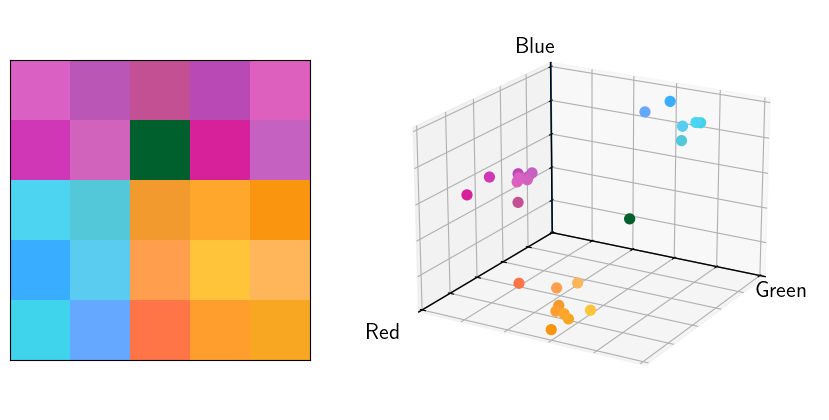

In [55]:
# Affichage

fig = plt.figure(figsize=(10,5), facecolor='w')

# Image
ax = fig.add_axes([0.05,0,.3,1])
ax.imshow(img)
ax.set_xticks([])
ax.set_yticks([])

# Affichage 3D
x = img[:,:,0].ravel()
y = img[:,:,1].ravel()
z = img[:,:,2].ravel()
c = np.reshape(img,(M*N,3))/255
ax = fig.add_axes([.43,0,.4,1], projection='3d')
ax.scatter(x, y, z, marker="o", c=c, s=50, alpha=1)
ax.set_xlabel("Red")
ax.set_ylabel("Green")
ax.set_zlabel("Blue")
ax.view_init(elev=20, azim=30)

# Hide axes ticks
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_zticklabels([])
ax.set_xlim([0, 256])
ax.set_ylim([0, 256])
ax.set_zlim([0, 256])
ax.xaxis._axinfo['juggled'] = (0,0,0)
ax.yaxis._axinfo['juggled'] = (1,1,1)
ax.zaxis._axinfo['juggled'] = (2,2,2)
ax.plot([0,256], [0,0], [0,0], 'k', linewidth=1)
ax.plot([0,0], [0,256], [0,0], 'k', linewidth=1)
ax.plot([0,0], [0,0], [0,256], [0,0], 'k', linewidth=1)

# Hack pour voir la totalité du graphe 3D
ax = fig.add_axes([.85,0.1,.01,.8])
ax.set_xticks([])
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

# Enregistrement et affichage
plt.savefig("3d-space.svg")
plt.show()